# Stable Diffusion XL with Hugging Face Diffusers

Contents:
- load SDXL from Hugging Face
- run text-to-image
- modify an existing image
- apply a LoRA adapter
- compare inference settings

## 1. Setup

Complete the [shared course setup](../../README.md#environment-setup) first. All dependencies are listed in the root [requirements.txt](../../requirements.txt). A compatible GPU is recommended for this demo.

Run the notebook from this directory so that `images/Cabin.png` can be found. Generated outputs are saved in `outputs/`.

## 2. Imports and configuration
Import libraries and pick device / dtype.

In [2]:
import math
import os
from io import BytesIO

import matplotlib.pyplot as plt
import requests
import torch
from PIL import Image
from diffusers import AutoPipelineForText2Image, AutoPipelineForImage2Image
import transformers, peft, accelerate

MODEL_ID = "stabilityai/stable-diffusion-xl-base-1.0"

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32

print(f"device: {device}")
print(f"dtype:  {dtype}")

/pfs/data6/home/ul/ul_student/ul_suh74/Deep_Learning_with_Pytorch/deep_learning_venv/lib64/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[transformers] `Siglip2ImageProcessorFast` is deprecated. The `Fast` suffix for image processors has been removed; use `Siglip2ImageProcessor` instead.


device: cuda
dtype:  torch.float16


## 3. Load the SDXL pipeline
Download the model and move it to the GPU.

In [3]:
pipe = AutoPipelineForText2Image.from_pretrained(
    MODEL_ID,
    torch_dtype=dtype,
    use_safetensors=True,
    variant="fp16" if device == "cuda" else None,
)
pipe = pipe.to(device)

# Helpful on memory-constrained GPUs. Usually not needed on an A100, but harmless.
pipe.enable_attention_slicing()

img2img_pipe = AutoPipelineForImage2Image.from_pipe(pipe)

print("SDXL pipeline loaded.")

/pfs/data6/home/ul/ul_student/ul_suh74/Deep_Learning_with_Pytorch/deep_learning_venv/lib64/python3.12/site-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
Loading pipeline components...: 100%|██████████| 7/7 [00:05<00:00,  1.34it/s]


SDXL pipeline loaded.


## Helper functions
Small utilities for loading, displaying, and saving images.

In [4]:
def make_generator(seed: int):
    if device == "cuda":
        return torch.Generator(device="cuda").manual_seed(seed)
    return torch.Generator().manual_seed(seed)

def show_images(images, titles=None, cols=2, figsize=(12, 8)):
    if not isinstance(images, (list, tuple)):
        images = [images]
    n = len(images)
    cols = min(cols, n)
    rows = math.ceil(n / cols)
    plt.figure(figsize=figsize)
    for i, img in enumerate(images, start=1):
        plt.subplot(rows, cols, i)
        plt.imshow(img)
        plt.axis("off")
        if titles and i - 1 < len(titles):
            plt.title(titles[i - 1])
    plt.tight_layout()
    plt.show()

def load_image_from_url(url: str) -> Image.Image:
    response = requests.get(url, timeout=30)
    response.raise_for_status()
    return Image.open(BytesIO(response.content)).convert("RGB")

def resize_for_sdxl(image: Image.Image, size=(1024, 1024)) -> Image.Image:
    return image.resize(size)

os.makedirs("outputs", exist_ok=True)

## 4. Example 1 — Text-to-image
Generate a first image from a text prompt.

100%|██████████| 35/35 [00:11<00:00,  3.14it/s]
/pfs/data6/home/ul/ul_student/ul_suh74/Deep_Learning_with_Pytorch/deep_learning_venv/lib64/python3.12/site-packages/diffusers/pipelines/stable_diffusion_xl/pipeline_stable_diffusion_xl.py:748: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(


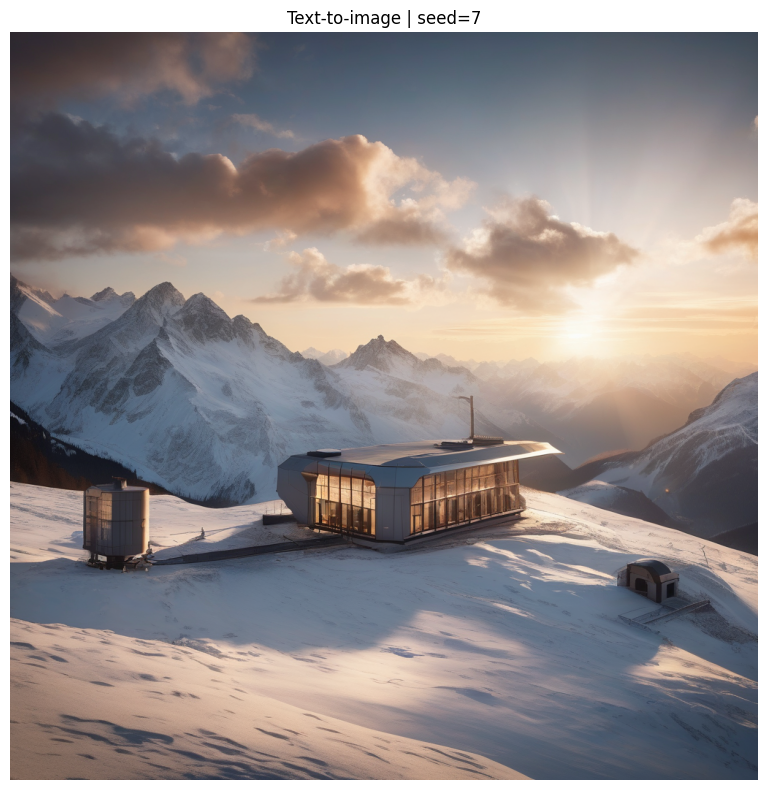

In [5]:
prompt = "A cinematic photograph of a research station in the Alps at sunrise, dramatic light, highly detailed, realistic"

seed = 7
generator = make_generator(seed)

image = pipe(
    prompt=prompt,
    negative_prompt="blurry, distorted, low quality",
    num_inference_steps=35,
    guidance_scale=7.0,
    generator=generator,
).images[0]

image.save("outputs/example_1_text_to_image.png")
show_images(image, titles=[f"Text-to-image | seed={seed}"], cols=1, figsize=(8, 8))

## 5. Example 2 — Image-to-image
Load an input image and transform it with a text prompt.

**Image provenance:** Generated with ChatGPT and provided by the course author. The bundled input is [Cabin.png](images/Cabin.png).

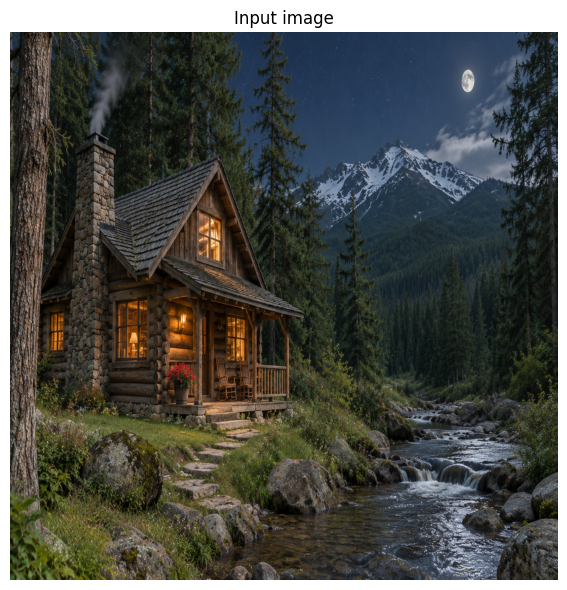

In [6]:
INPUT_IMAGE_PATH = "images/Cabin.png"

input_image = Image.open(INPUT_IMAGE_PATH).convert("RGB")
input_image = resize_for_sdxl(input_image)

show_images(input_image, titles=["Input image"], cols=1, figsize=(6, 6))

100%|██████████| 30/30 [00:05<00:00,  5.90it/s]
/pfs/data6/home/ul/ul_student/ul_suh74/Deep_Learning_with_Pytorch/deep_learning_venv/lib64/python3.12/site-packages/diffusers/pipelines/stable_diffusion_xl/pipeline_stable_diffusion_xl_img2img.py:896: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
100%|██████████| 90/90 [00:15<00:00,  5.82it/s]


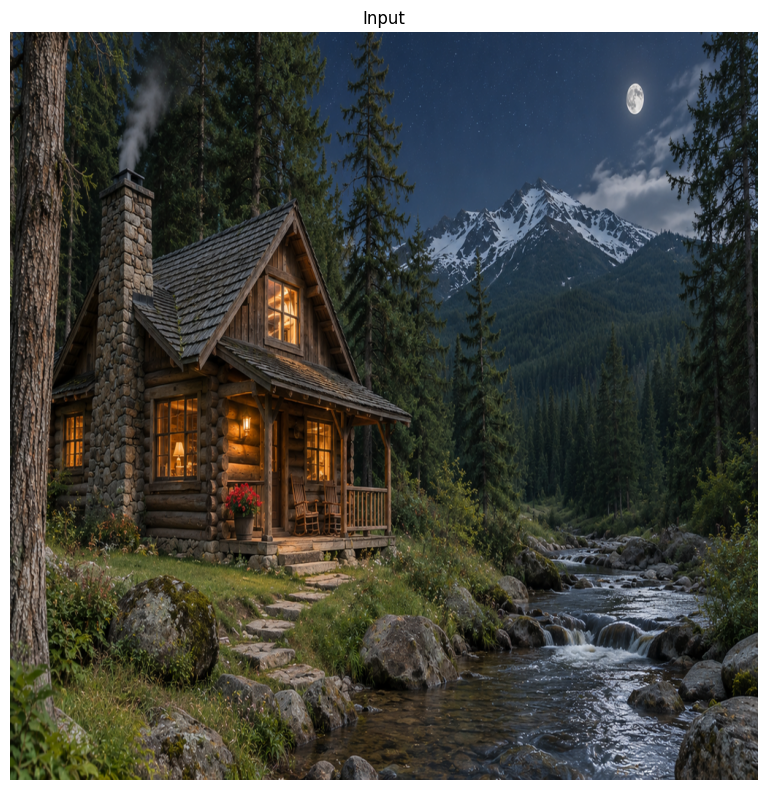

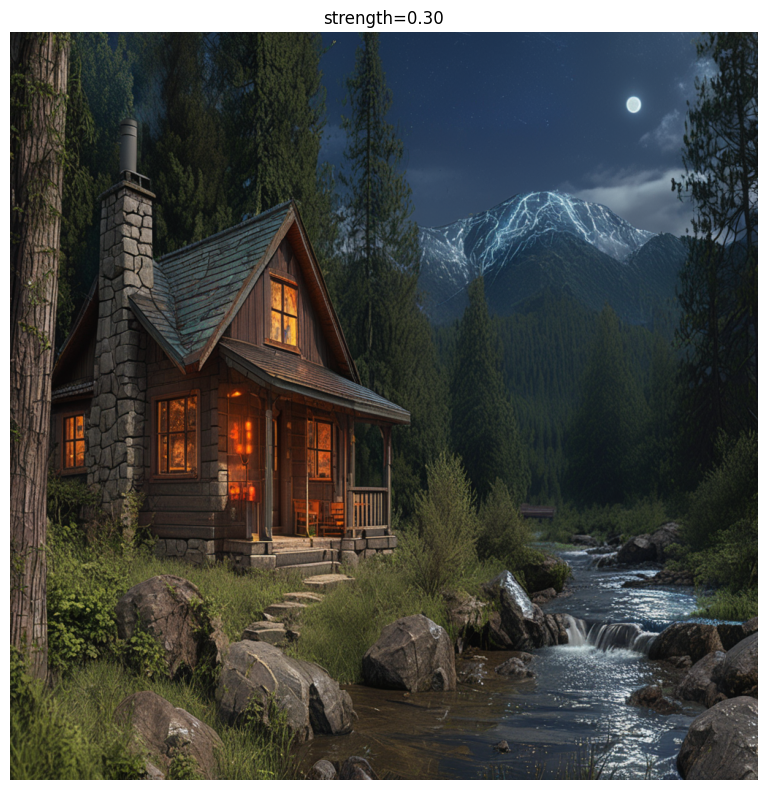

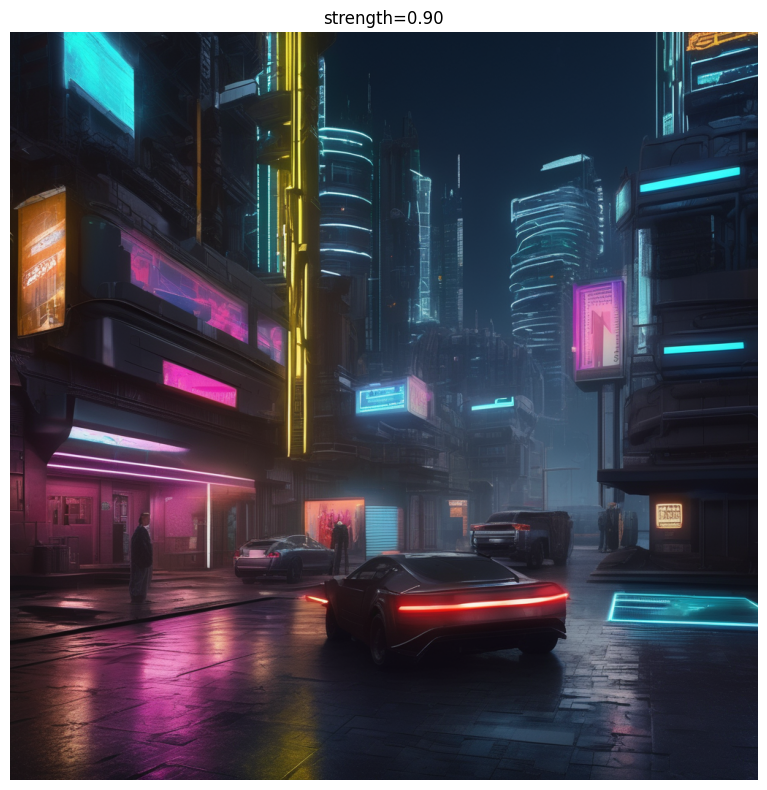

In [7]:
img2img_prompt = "Transform this image into a cinematic sci-fi scene at night, neon lights, highly detailed, realistic textures"

seed = 21
generator = make_generator(seed)

img2img_low = img2img_pipe(
    prompt=img2img_prompt,
    image=input_image,
    strength=0.30,
    guidance_scale=10.0,
    num_inference_steps=100,
    generator=generator,
).images[0]

generator = make_generator(seed)
img2img_high = img2img_pipe(
    prompt=img2img_prompt,
    image=input_image,
    strength=0.90,
    guidance_scale=10.0,
    num_inference_steps=100,
    generator=generator,
).images[0]

img2img_low.save("outputs/example_2_img2img_strength_030.png")
img2img_high.save("outputs/example_2_img2img_strength_090.png")

show_images(
    input_image,
    titles=["Input"],
    cols=1,
    figsize=(8, 8),
)

show_images(
    img2img_low,
    titles=["strength=0.30"],
    cols=1,
    figsize=(8, 8),
)

show_images(
    img2img_high,
    titles=["strength=0.90"],
    cols=1,
    figsize=(8, 8),
)

## 6. Example 3 — Apply a LoRA adapter
Compare the same prompt without and with a LoRA.

100%|██████████| 50/50 [00:08<00:00,  5.80it/s]


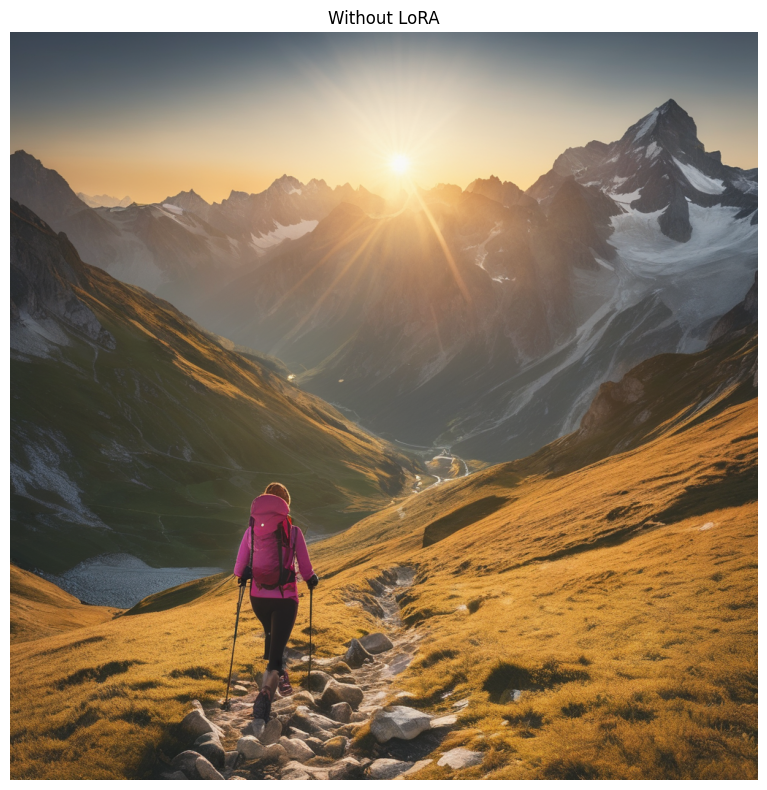

In [8]:
lora_prompt = "A woman hiking in the alps with the sun rising"

seed = 123
generator = make_generator(seed)

baseline_image = pipe(
    prompt=lora_prompt,
    negative_prompt="blurry, distorted, low quality",
    num_inference_steps=50,
    guidance_scale=7,
    generator=generator,
).images[0]

baseline_image.save("outputs/example_3_lora_baseline.png")
show_images(baseline_image, titles=["Without LoRA"], cols=1, figsize=(8, 8))

In [9]:
LORA_REPO_ID = "ostris/watercolor_style_lora_sdxl"
LORA_WEIGHT_NAME = None

pipe.unload_lora_weights()

load_kwargs = {}
if LORA_WEIGHT_NAME:
    load_kwargs["weight_name"] = LORA_WEIGHT_NAME

pipe.load_lora_weights(LORA_REPO_ID, **load_kwargs)

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
No LoRA keys associated to CLIPTextModelWithProjection found with the prefix='text_encoder_2'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModelWithProjection related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


100%|██████████| 50/50 [00:09<00:00,  5.21it/s]


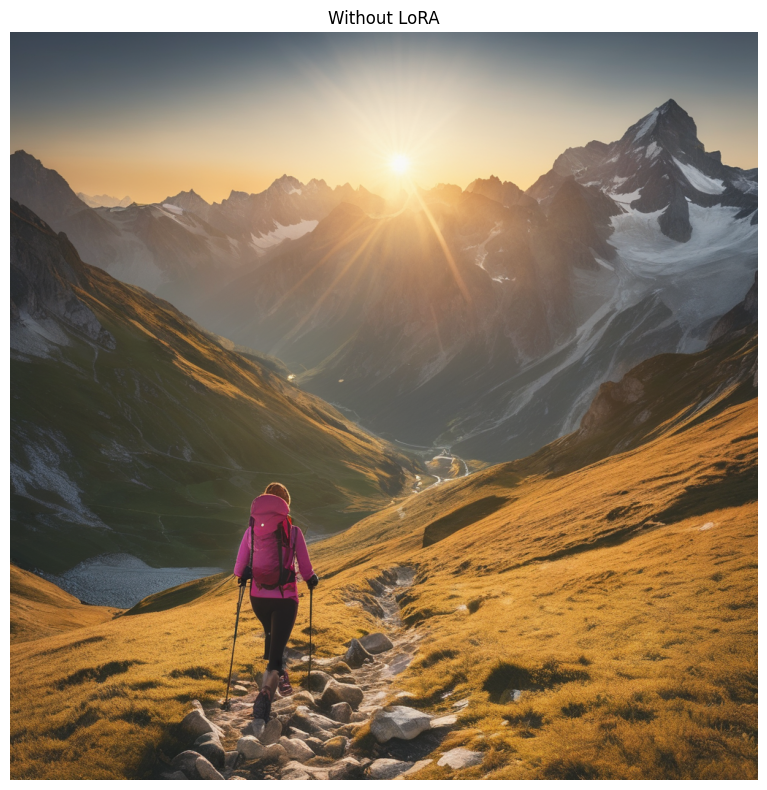

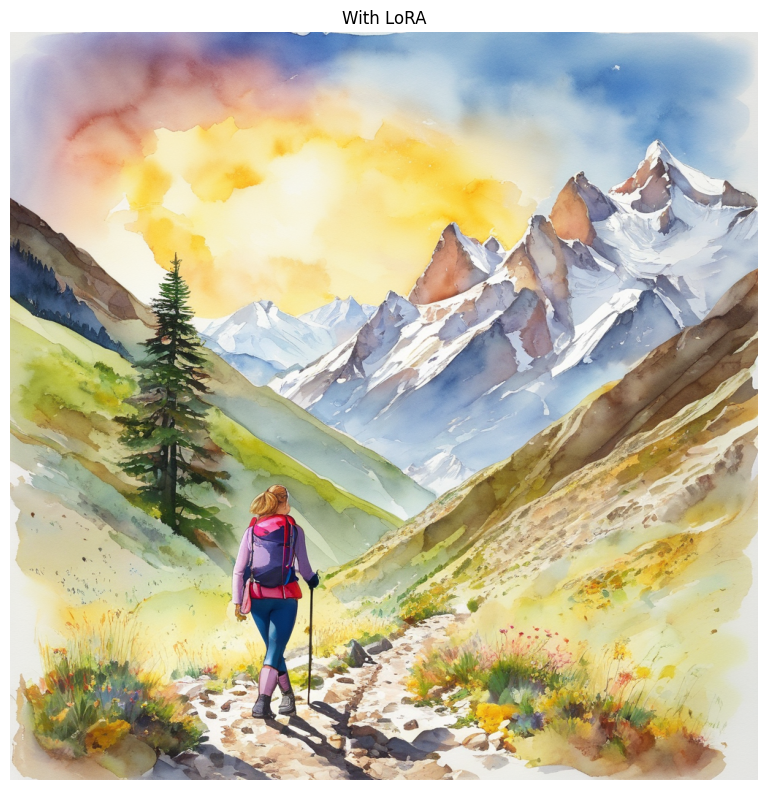

In [10]:
generator = make_generator(seed)

prompt_with_lora = f"{lora_prompt}"

lora_image = pipe(
    prompt=prompt_with_lora,
    negative_prompt="blurry, distorted, low quality",
    num_inference_steps=50,
    guidance_scale=7,
    cross_attention_kwargs={"scale": 0.8},
    generator=generator,
).images[0]

lora_image.save("outputs/example_3_lora_applied.png")

show_images(
    baseline_image,
    titles=["Without LoRA"],
    figsize=(8, 8),
)

show_images(
    lora_image,
    titles= ["With LoRA"],
    figsize=(8, 8),
)

## 7. Example 4 — Tune inference parameters
Change one variable at a time and compare outputs side by side.

100%|██████████| 200/200 [00:39<00:00,  5.09it/s]


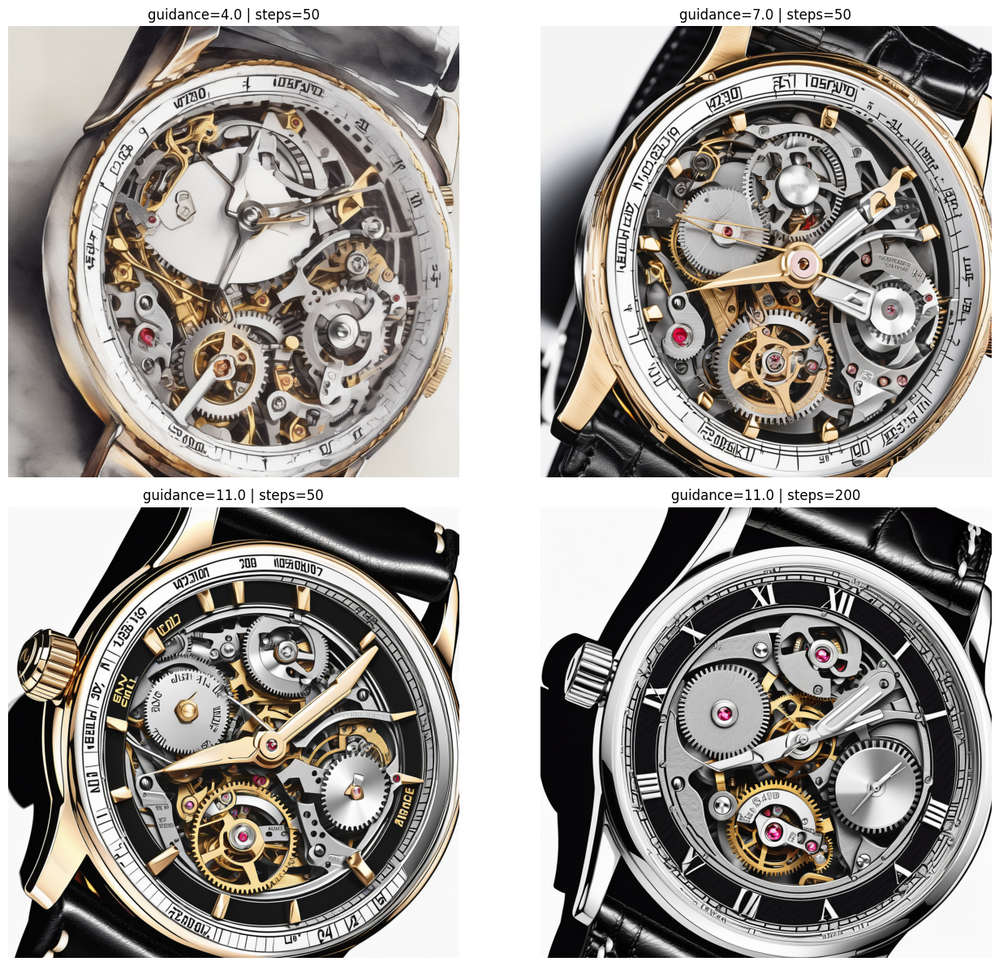

In [11]:
compare_prompt = "A detailed studio photo of a mechanical watch on black velvet, dramatic lighting, ultra realistic"

configs = [
    {"guidance_scale": 4.0, "num_inference_steps": 50},
    {"guidance_scale": 7.0, "num_inference_steps": 50},
    {"guidance_scale": 11.0, "num_inference_steps": 50},
    {"guidance_scale": 11.0, "num_inference_steps": 200},
]

images = []
titles = []

for cfg in configs:
    generator = make_generator(999)
    img = pipe(
        prompt=compare_prompt,
        negative_prompt="blurry, distorted, low quality",
        guidance_scale=cfg["guidance_scale"],
        num_inference_steps=cfg["num_inference_steps"],
        generator=generator,
    ).images[0]
    images.append(img)
    titles.append(f"guidance={cfg['guidance_scale']} | steps={cfg['num_inference_steps']}")

show_images(images, titles=titles, cols=2, figsize=(14, 12))

## 8. Practical tips

- Use the same seed when comparing settings.
- Guidance scale controls how strongly the model follows the prompt.
- More steps help only up to a point.
- In img2img, `strength` is usually the most important parameter.
- LoRA is a lightweight way to adapt style or behavior.
- For fair comparisons, change one variable at a time.
- Use half precision on GPU for SDXL inference.

## 9. Wrap-up

This notebook showed:
- text-to-image with SDXL
- image-to-image with different `strength` values
- a before/after LoRA comparison
- a compact parameter sweep